Step 1: Import Libraries and Load Dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Load Auto MPG dataset (UCI repository, via seaborn's bundled copy or local CSV)
#url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv'
url = '../../data/auto-mpg-dataset.csv'
df = pd.read_csv(url)
print(df.head())
print(df.describe())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
              mpg   cylinders  displacement  horsepower       weight  \
count  398.000000  398.000000    398.000000  392.000000   398.000000   
mean    23.514573    5.454774    193.425879  104.469388  2970.424623   
std      7.815984    1.701004    104.269838   38.491160   846.8

Step 2: Exploratory Data Analysis

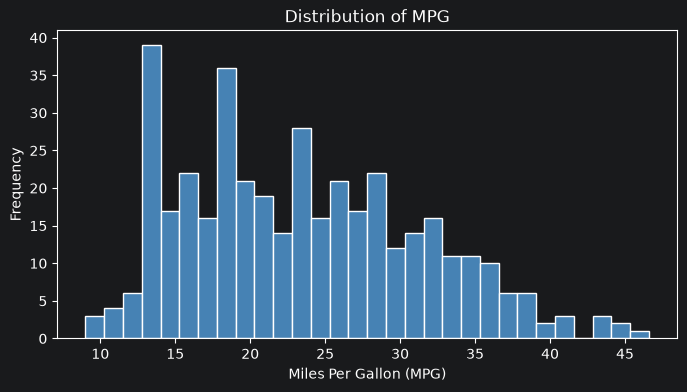

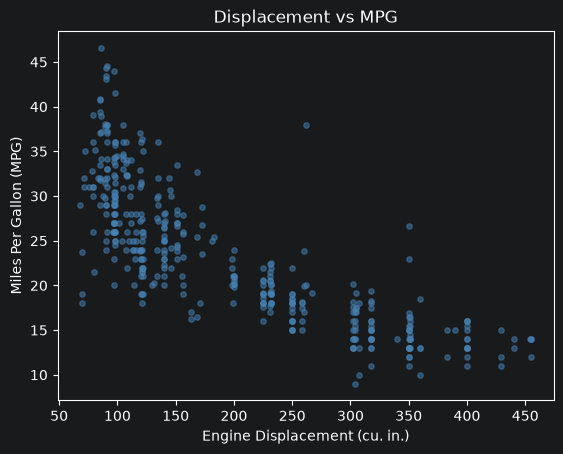

In [ ]:
# Examine the target variable distribution
plt.figure(figsize=(8, 4))
plt.hist(df['mpg'], bins=30, color='steelblue', edgecolor='white')
plt.title('Distribution of MPG')
plt.xlabel('Miles Per Gallon (MPG)')
plt.ylabel('Frequency')
plt.show()

# Scatter plot of chosen feature vs target
plt.scatter(df['displacement'], df['mpg'], alpha=0.5, s=15, color='steelblue')
plt.xlabel('Engine Displacement (cu. in.)')
plt.ylabel('Miles Per Gallon (MPG)')
plt.title('Displacement vs MPG')
plt.show()

Step 3: Data Preprocessing

In [ ]:
# Drop rows with missing values
df = df.dropna(subset=['displacement', 'mpg'])
# Select single feature and target
X = df[['displacement']].values
y = df['mpg'].values
# Train-test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=4)


Step 4: Baseline — Simple Linear Regression

In [ ]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)
y_pred_lin = lin_model.predict(X_test)
mse_lin = mean_squared_error(y_test, y_pred_lin)
r2_lin = r2_score(y_test, y_pred_lin)
print(f'Linear Regression => MSE={mse_lin:.4f} RMSE={mse_lin**0.5:.4f} R2={r2_lin:.4f}')

Linear Regression => MSE=18.9535 RMSE=4.3536 R2=0.7053


Step 5: Polynomial Regression of Varying Degrees

In [ ]:
degrees = [1, 2, 3, 4, 6, 8]
results = []
models = {}
for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    model = LinearRegression()
    model.fit(X_train_poly, y_train)
    y_pred = model.predict(X_test_poly)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    results.append((d, mse, mse**0.5, r2))
    models[d] = (poly, model)
    print(f'Degree {d:2d} => MSE={mse:.4f} RMSE={mse**0.5:.4f} R2={r2:.4f}')

Degree  1 => MSE=18.9535 RMSE=4.3536 R2=0.7053
Degree  2 => MSE=15.4251 RMSE=3.9275 R2=0.7602
Degree  3 => MSE=16.8008 RMSE=4.0989 R2=0.7388
Degree  4 => MSE=19.5595 RMSE=4.4226 R2=0.6959
Degree  6 => MSE=26.8770 RMSE=5.1843 R2=0.5821
Degree  8 => MSE=34.4326 RMSE=5.8679 R2=0.4647


Step 6: Compare Polynomial Models with Linear Regression

                    Degree        MSE      RMSE        R2
0  Linear (deg=1 baseline)  18.953483  4.353560  0.705319
1                        1  18.953483  4.353560  0.705319
2                        2  15.425065  3.927476  0.760177
3                        3  16.800797  4.098878  0.738788
4                        4  19.559465  4.422608  0.695897
5                        6  26.876977  5.184301  0.582128
6                        8  34.432640  5.867933  0.464655


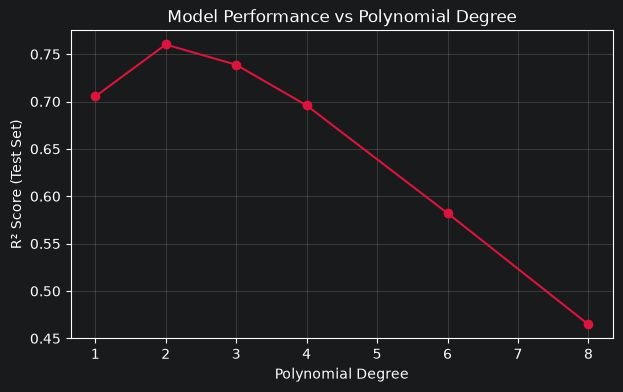

In [ ]:
results_df = pd.DataFrame(results, columns=['Degree', 'MSE', 'RMSE', 'R2'])
results_df.loc[-1] = ['Linear (deg=1 baseline)', mse_lin, mse_lin**0.5, r2_lin]
results_df = results_df.sort_index().reset_index(drop=True)
print(results_df)
plt.figure(figsize=(7, 4))
plt.plot(degrees, [r[3] for r in results], marker='o', color='crimson')
plt.xlabel('Polynomial Degree')
plt.ylabel('R² Score (Test Set)')
plt.title('Model Performance vs Polynomial Degree')
plt.grid(alpha=0.3)
plt.show()

Step 7: Visualization — Fitted Curves

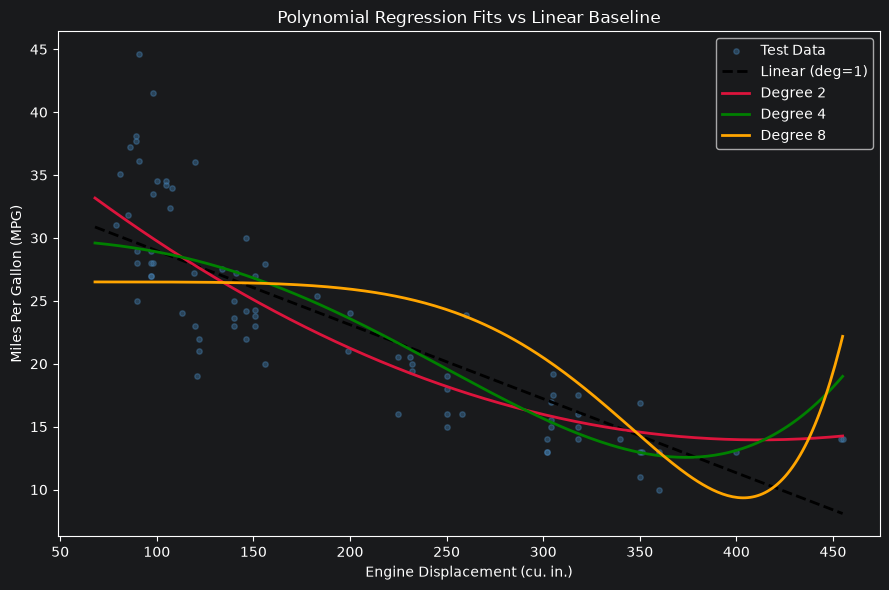

In [ ]:
xs = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
plt.figure(figsize=(9, 6))
plt.scatter(X_test, y_test, alpha=0.4, s=15, color='steelblue', label='Test Data')
# Linear baseline
plt.plot(xs, lin_model.predict(xs), color='black', lw=2, linestyle='--', label='Linear (deg=1)')
# A few representative polynomial degrees
for d, color in zip([2, 4, 8], ['crimson', 'green', 'orange']):
    poly, model = models[d]
    xs_poly = poly.transform(xs)
    plt.plot(xs, model.predict(xs_poly), color=color, lw=2, label=f'Degree {d}')
plt.xlabel('Engine Displacement (cu. in.)')
plt.ylabel('Miles Per Gallon (MPG)')
plt.title('Polynomial Regression Fits vs Linear Baseline')
plt.legend()
plt.tight_layout()
plt.show()